# Regressão - Previsão do Custo de Plano de Saúde

## 1. Definição do problema

Planos de saúde precisam estimar quanto cada cliente deve custar em despesas médicas para definir o valor da mensalidade. Se o valor for baixo demais, a empresa tem prejuízo, e se for alto demais, perde clientes. Entender quais características aumentam o custo também ajuda em campanhas de prevenção, como programas para parar de fumar.

**Pergunta principal:** É possível prever o custo médico anual de uma pessoa a partir de características como idade, IMC e se ela é fumante?

**Tipo de problema:** Regressão, pois a variável alvo é um valor numérico (custo em dólares).

## 2. Apresentação da base de dados

- **Nome:** Medical Cost Personal Dataset (arquivo `insurance.csv`)
- **Origem:** base usada no livro *Machine Learning with R*, de Brett Lantz. Os dados foram simulados com base em estatísticas demográficas dos Estados Unidos. Disponível no Kaggle: https://www.kaggle.com/datasets/mirichoi0218/insurance
- **Registros:** 1.338 pessoas
- **Colunas:** 7 (6 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| age | idade | idade da pessoa |
| sex | sexo | female (feminino) ou male (masculino) |
| bmi | imc | índice de massa corporal (peso / altura²) |
| children | filhos | número de filhos cobertos pelo plano |
| smoker | fumante | yes (sim) ou no (não) |
| region | regiao | região onde mora nos EUA (northeast, northwest, southeast, southwest) |
| charges | custo | **variável alvo**: custo médico anual cobrado pelo plano (em dólares) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados
df = pd.read_csv('../dados/insurance.csv')

# renomeando as colunas para facilitar a leitura
df = df.rename(columns={
    'age': 'idade',
    'sex': 'sexo',
    'bmi': 'imc',
    'children': 'filhos',
    'smoker': 'fumante',
    'region': 'regiao',
    'charges': 'custo'
})

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 1338
Colunas: 7


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,idade,sexo,imc,filhos,fumante,regiao,custo
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# tipos de dados
df.dtypes

idade        int64
sexo           str
imc        float64
filhos       int64
fumante        str
regiao         str
custo      float64
dtype: object

In [5]:
# valores ausentes
df.isnull().sum()

idade      0
sexo       0
imc        0
filhos     0
fumante    0
regiao     0
custo      0
dtype: int64

In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicados: 1


,idade,sexo,imc,filhos,fumante,regiao,custo
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [7]:
# estatisticas basicas
df.describe().round(2)

,idade,imc,filhos,custo
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [8]:
# quantidade em cada categoria
print(df['sexo'].value_counts())
print()
print(df['fumante'].value_counts())
print()
print(df['regiao'].value_counts())

sexo
male      676
female    662
Name: count, dtype: int64

fumante
no     1064
yes     274
Name: count, dtype: int64

regiao
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


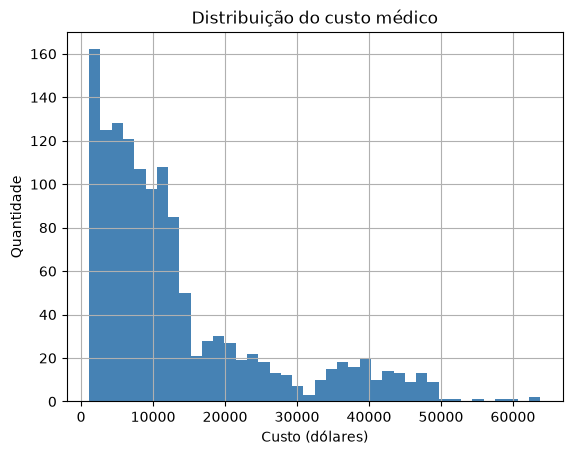

In [9]:
# distribuicao do custo
df['custo'].hist(bins=40, color='steelblue')
plt.title('Distribuição do custo médico')
plt.xlabel('Custo (dólares)')
plt.ylabel('Quantidade')
plt.show()

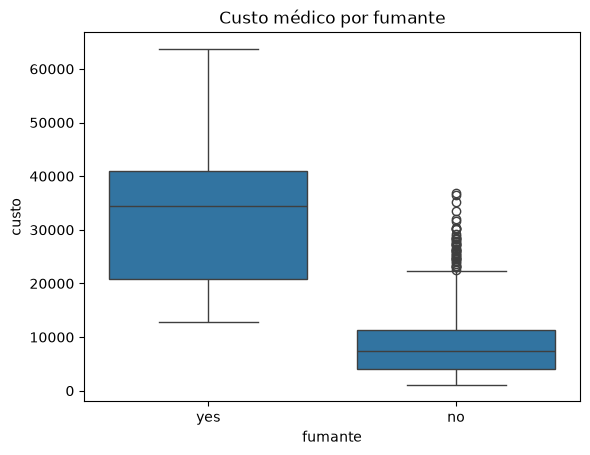

fumante
no      8434.27
yes    32050.23
Name: custo, dtype: float64


In [10]:
# custo de fumantes e nao fumantes
sns.boxplot(data=df, x='fumante', y='custo')
plt.title('Custo médico por fumante')
plt.show()

print(df.groupby('fumante')['custo'].mean().round(2))

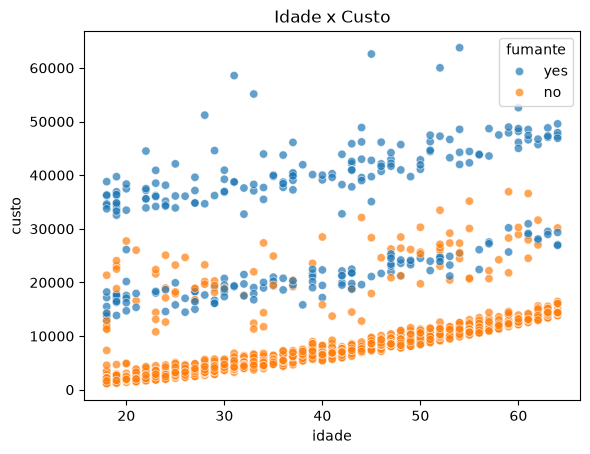

In [11]:
# idade x custo, separando fumantes
sns.scatterplot(data=df, x='idade', y='custo', hue='fumante', alpha=0.7)
plt.title('Idade x Custo')
plt.show()

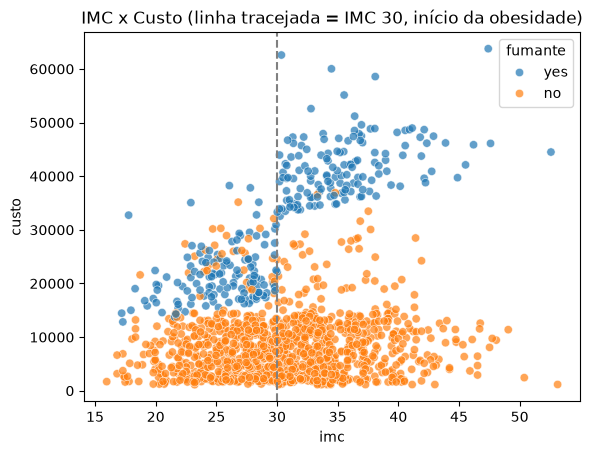

In [12]:
# imc x custo, separando fumantes
sns.scatterplot(data=df, x='imc', y='custo', hue='fumante', alpha=0.7)
plt.axvline(30, color='gray', linestyle='--')
plt.title('IMC x Custo (linha tracejada = IMC 30, início da obesidade)')
plt.show()

In [13]:
# custo medio por fumante e obesidade
df_grupos = df.copy()
df_grupos['obeso'] = np.where(df_grupos['imc'] >= 30, 'obeso', 'não obeso')
df_grupos.groupby(['fumante', 'obeso'])['custo'].mean().round(2)

fumante  obeso    
no       não obeso     7977.03
         obeso         8842.69
yes      não obeso    21363.22
         obeso        41557.99
Name: custo, dtype: float64

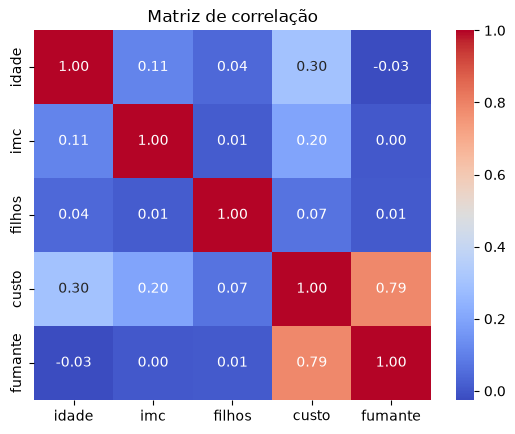

In [14]:
# matriz de correlacao (fumante convertido para 0 e 1 so para este grafico)
df_corr = df[['idade', 'imc', 'filhos', 'custo']].copy()
df_corr['fumante'] = (df['fumante'] == 'yes').astype(int)

sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 1.338 registros, nenhum valor ausente e **1 registro duplicado** (uma pessoa de 19 anos com exatamente os mesmos dados e custo).
- O custo vai de 1.122 a 63.770 dólares, com média de 13.270 e mediana de 9.382. O histograma mostra que a maioria das pessoas tem custo baixo e poucas têm custo muito alto.
- **Ser fumante é o fator mais importante** (correlação de 0,79). Os fumantes custam em média 32.050 dólares, quase 4 vezes mais que os não fumantes (8.434). Apenas 20,5% das pessoas da base são fumantes.
- A **idade** também aumenta o custo (correlação de 0,30). No gráfico de idade x custo aparecem três "faixas" separadas: não fumantes embaixo, fumantes em cima e uma faixa no meio.
- O **IMC** sozinho tem correlação fraca (0,20), mas o gráfico mostra que ele faz muita diferença **para os fumantes**: fumantes obesos (IMC 30 ou mais) custam em média 41.558, contra 21.363 dos fumantes não obesos. Para não fumantes a obesidade quase não muda o custo (8.843 contra 7.977).
- Sexo, região e número de filhos têm pouca influência no custo.

## 4. Preparação dos dados

Decisões tomadas:

1. **Valores ausentes:** a base não tem valores ausentes, então nada precisou ser preenchido.
2. **Duplicado removido:** o registro repetido foi removido. Como a base é pequena e todos os dados são iguais (inclusive o custo com várias casas decimais), é muito provável que seja a mesma pessoa registrada duas vezes.
3. **Sexo e fumante:** como só têm duas opções, foram transformados em 0 e 1 (sexo: 0 = feminino, 1 = masculino; fumante: 0 = não, 1 = sim).
4. **Região:** tem 4 categorias sem ordem entre elas, então foi usado **one-hot encoding**, criando uma coluna de 0 ou 1 para cada região.
5. **Valores altos de custo:** não foram removidos. Os custos altos são reais (principalmente de fumantes) e são justamente os casos que o modelo precisa aprender a prever.
6. **Treino e teste:** 80% treino e 20% teste.
7. **Padronização:** `StandardScaler`, porque a idade vai até 64 e o IMC até 53, enquanto as outras colunas são 0 ou 1. Isso é importante para o KNN e a Ridge.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# removendo o registro duplicado
df = df.drop_duplicates()
print('Linhas depois de remover o duplicado:', df.shape[0])

# transformando sexo e fumante em 0 e 1
df['sexo'] = (df['sexo'] == 'male').astype(int)
df['fumante'] = (df['fumante'] == 'yes').astype(int)

# one-hot encoding da regiao
df = pd.get_dummies(df, columns=['regiao'], dtype=int)

df.head()

Linhas depois de remover o duplicado: 1337


,idade,sexo,imc,filhos,fumante,custo,regiao_northeast,regiao_northwest,regiao_southeast,regiao_southwest
0,19,0,27.900,0,1,16884.92400,0,0,0,1
1,18,1,33.770,1,0,1725.55230,0,0,1,0
2,28,1,33.000,3,0,4449.46200,0,0,1,0
3,33,1,22.705,0,0,21984.47061,0,1,0,0
4,32,1,28.880,0,0,3866.85520,0,1,0,0


In [16]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='custo')
y = df['custo']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)
print()
print('Proporção de fumantes no treino:', round(X_treino['fumante'].mean(), 3))
print('Proporção de fumantes no teste:', round(X_teste['fumante'].mean(), 3))

Treino: (1069, 9)
Teste: (268, 9)

Proporção de fumantes no treino: 0.2
Proporção de fumantes no teste: 0.224


## 5. Escolha dos modelos

Foram usados os mesmos 5 modelos de regressão dos outros notebooks:

- **Regressão Linear:** modelo base, simples e fácil de interpretar. Cada coeficiente mostra quanto o custo aumenta para cada variável.
- **Ridge:** regressão linear com penalização, para comparar se ela ajuda em uma base pequena.
- **Árvore de Decisão Regressora:** consegue capturar combinações como "fumante e obeso", que a análise exploratória mostrou que são importantes e que uma reta não captura bem. Limitada a profundidade 5.
- **Random Forest Regressor:** média de várias árvores. Também foi limitada a profundidade 5, porque sem limite ela chegou a R² de 0,97 no treino e só 0,88 no teste, sinal de que estava decorando os dados.
- **KNN Regressor:** prevê o custo como a média das 5 pessoas mais parecidas. Foram usados 5 vizinhos porque a base é pequena.

## 6. Treinamento dos modelos

- **Dados de treino:** 1.069 pessoas (80%)
- **Dados de teste:** 268 pessoas (20%)

Cada modelo aprende com os dados de treino (`fit`) e depois prevê o custo das pessoas do teste (`predict`).

In [17]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

modelos = {
    'Regressão Linear': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(max_depth=5, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Linear - treinado
Ridge - treinado
Árvore de Decisão - treinado


Random Forest - treinado
KNN - treinado
